# Klasifikasi Hate Speech dengan Qwen3.5-9B

In [ ]:
# # Pemeriksaan awal pada kernel Modal yang dipilih melalui VS Code.
# import os
# from pathlib import Path
# import torch

# if not Path('/workspace').is_dir():
#     raise RuntimeError('Pilih kernel Jupyter Modal melalui Existing Jupyter Server di VS Code.')
# os.chdir('/workspace')
# required_inputs = [Path('prompt/EN_PROMPT.md')] + [
#     Path('data/en-splitting') / f'en-{split}.csv' for split in ('train', 'val', 'test')
# ]
# missing_inputs = [str(path) for path in required_inputs if not path.is_file()]
# if missing_inputs:
#     raise FileNotFoundError(f'Input EN-EN belum lengkap pada Volume: {missing_inputs}')
# if not torch.cuda.is_available():
#     raise RuntimeError('Kernel Modal harus memiliki GPU CUDA.')
# print('Folder kerja:', Path.cwd())
# print('GPU:', torch.cuda.get_device_name(0), '| BF16:', torch.cuda.is_bf16_supported())
# print('Input EN-EN ditemukan:', [str(path) for path in required_inputs])


## 1. Library


In [ ]:
# import subprocess
# import sys

# subprocess.check_call([sys.executable, '-m', 'pip', 'install',
#     'transformers==5.20.2', 'peft==0.21.2', 'accelerate==1.15.0',
#     'datasets>=4,<6', 'pandas>=2.2,<3', 'scikit-learn>=1.6,<2', 'matplotlib>=3.9,<4'])
# INSTALL_FAST_KERNELS = False
# if INSTALL_FAST_KERNELS:
#     import os
#     os.environ.setdefault('MAX_JOBS', '4')
#     subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--no-build-isolation',
#                            'flash-linear-attention==0.5.2', 'causal-conv1d==1.7.0'])
# print('Restart kernel, lalu lanjut bagian 2.')


In [ ]:
import os
os.environ.update(TOKENIZERS_PARALLELISM='false', USE_TF='0', USE_FLAX='0')

import gc
import hashlib
import json
import math
import re
import unicodedata
from contextlib import nullcontext
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from uuid import uuid4
from zipfile import ZipFile, ZIP_DEFLATED

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
import peft
from datasets import Dataset
from huggingface_hub import HfApi
from IPython.display import FileLink, display
from peft import LoraConfig, get_peft_model
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
from transformers import AutoTokenizer, Qwen3_5ForCausalLM, Trainer, TrainingArguments, EarlyStoppingCallback, set_seed


## 2. Konfigurasi

In [ ]:
DATA_LANGUAGE = 'it'
PROMPT_LANGUAGE = 'it'
RUN_ZERO_SHOT_BASELINE = True
INPUT_MODE = 'comment_only'  
MAX_LENGTH = 1024
BATCH_SIZE = 4
GRAD_ACCUM = 4  
EVAL_BATCH_SIZE = 4  
EPOCHS = 5
LEARNING_RATE = 1e-4
SEED = 42
MODEL_NAME = 'Qwen/Qwen3.5-9B'
MODEL_REVISION = 'c202236235762e1c871ad0ccb60c8ee5ba337b9a'  # Revisi pada run terdahulu.
LABELS = ['no', 'yes_implicit', 'yes_explicit']

LABEL_TO_ANSWER = {'no': '0', 'yes_explicit': '1', 'yes_implicit': '2'}
LANGUAGES = {'en': 'English', 'it': 'Italian', 'nl': 'Dutch'}


assert DATA_LANGUAGE in LANGUAGES, 'DATA_LANGUAGE harus en, it, atau nl.'
assert PROMPT_LANGUAGE in LANGUAGES, 'PROMPT_LANGUAGE harus en, it, atau nl.'
assert INPUT_MODE in {'comment_only', 'with_video_context'}
assert MAX_LENGTH >= 256 and min(BATCH_SIZE, GRAD_ACCUM, EVAL_BATCH_SIZE) > 0

set_seed(SEED)
OUT = Path('results') / f"qwen35_prompt-{PROMPT_LANGUAGE}_data-{DATA_LANGUAGE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid4().hex[:8]}"
OUT.mkdir(parents=True, exist_ok=False)
print('GPU:', torch.cuda.get_device_name(0))
print('Bahasa data:', DATA_LANGUAGE, '| Bahasa prompt:', PROMPT_LANGUAGE)
print('Hasil:', OUT)

PROMPT_NAME = f'{PROMPT_LANGUAGE.upper()}_PROMPT.md'
PROMPT_PATH = Path('prompt') / PROMPT_NAME
PROMPT_BYTES = PROMPT_PATH.read_bytes()
SYSTEM_PROMPT = PROMPT_BYTES.decode('utf-8-sig').strip()

GPU: NVIDIA H200
Bahasa data: it | Bahasa prompt: it
Hasil: results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951
Prompt: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/prompt/IT_PROMPT.md


## 3. Baca dan periksa data


In [ ]:
splits = ('train', 'val', 'test')
names = [f'{DATA_LANGUAGE}-{split}.csv' for split in splits]
split_folder = f'{DATA_LANGUAGE}-splitting'
candidates = [
    Path('.'), Path('data'), Path(split_folder),
    Path('data') / split_folder, Path('Analisis/data') / split_folder,
    Path('../data') / split_folder,
]

for DATA_DIR in candidates:
    present = [(DATA_DIR / name).is_file() for name in names]
    if any(present):
        if not all(present):
            raise FileNotFoundError(f'Lengkapi {names} dalam folder {DATA_DIR.resolve()}.')
        break
else:
    raise FileNotFoundError(f'Upload {names} ke {Path.cwd()}. Periksa DATA_LANGUAGE.')

required = {'StereoQueerEval_id', 'yt_comment', 'hate_speech'}
video_columns = {'yt_title', 'yt_description'}
if INPUT_MODE == 'with_video_context':
    required |= video_columns

frames, source_hashes, audit_keys = {}, {}, {}
normalize = lambda text: re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(text)).casefold()).strip()

for split, name in zip(splits, names):
    csv_path = DATA_DIR / name
    frame = pd.read_csv(csv_path, dtype=str, keep_default_na=False, encoding='utf-8-sig')

    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{name}: kolom wajib tidak tersedia: {sorted(missing)}.')
    if frame.empty:
        raise ValueError(f'{name}: data kosong.')
    for column in ('StereoQueerEval_id', 'yt_comment'):
        if frame[column].str.strip().eq('').any():
            raise ValueError(f'{name}: {column} berisi nilai kosong.')
    if frame['StereoQueerEval_id'].duplicated().any():
        raise ValueError(f'{name}: terdapat ID duplikat.')
    if set(frame['hate_speech']) != set(LABELS):
        raise ValueError(f'{name}: kelas tidak sesuai dengan LABELS.')

    audit_keys[split] = {
        'id': set(frame['StereoQueerEval_id']),
        'comment': set(frame['yt_comment'].map(normalize)),
    }
    if video_columns <= set(frame.columns):
        contexts = zip(frame['yt_title'].map(normalize), frame['yt_description'].map(normalize))
        audit_keys[split]['video'] = {pair for pair in contexts if any(pair)}

    frames[split] = frame
    source_hashes[name] = hashlib.sha256(csv_path.read_bytes()).hexdigest()

for left, right in combinations(frames, 2):
    shared_keys = audit_keys[left].keys() & audit_keys[right].keys()
    for key in shared_keys:
        if audit_keys[left][key] & audit_keys[right][key]:
            raise ValueError(f'Overlap {key}: {left} dan {right}. Periksa split asli.')

print('Folder CSV:', DATA_DIR.resolve())
class_counts = pd.DataFrame({split: frame['hate_speech'].value_counts() for split, frame in frames.items()}).T
display(class_counts)


Folder CSV: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/data/it-splitting


hate_speech,no,yes_explicit,yes_implicit
train,822,476,401
val,105,59,56
test,233,124,124


## 4. Persiapan Data


In [3]:
MODEL_COMMIT = HfApi().model_info(MODEL_NAME, revision=MODEL_REVISION).sha
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_COMMIT)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right'
EOS_ID = tokenizer.convert_tokens_to_ids('<|im_end|>')
assert tokenizer.convert_ids_to_tokens(EOS_ID) == '<|im_end|>'
answers = {label: tokenizer.encode(LABEL_TO_ANSWER[label], add_special_tokens=False) + [EOS_ID]
           for label in LABELS}

def prompt_ids(content):
    return tokenizer.apply_chat_template([
        {'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': content}],
        tokenize=True, return_dict=False, add_generation_prompt=True, enable_thinking=False)

def encode(row):
    content = f"Language: {LANGUAGES[DATA_LANGUAGE]}\nComment:\n{row['yt_comment']}"
    if INPUT_MODE == 'with_video_context':
        content += f"\n\nVideo title:\n{row['yt_title']}\nVideo description:\n{row['yt_description']}"
    tokens = tokenizer.encode(content, add_special_tokens=False)
    budget = MAX_LENGTH - max(map(len, answers.values()))
    available = budget - len(prompt_ids('')) - 8
    if available < 16:
        raise ValueError('Naikkan MAX_LENGTH agar instruksi dan komentar muat.')
    keep = min(len(tokens), available)
    prompt = prompt_ids(content if keep == len(tokens) else tokenizer.decode(tokens[:keep]))
    while len(prompt) > budget and keep > 8:
        keep -= 8
        prompt = prompt_ids(tokenizer.decode(tokens[:keep]))
    if len(prompt) > budget:
        raise ValueError('Prompt terlalu panjang untuk MAX_LENGTH.')
    return {'id': row.get('StereoQueerEval_id', 'new'), 'prompt': prompt,
            'gold': row.get('hate_speech'), 'truncated': keep < len(tokens)}

def example(record, label=None):
    answer = answers[record['gold'] if label is None else label]
    return {'input_ids': record['prompt'] + answer, 'labels': [-100] * len(record['prompt']) + answer}

def collate(features):
    length = math.ceil(max(len(row['input_ids']) for row in features) / 8) * 8
    batch = {'input_ids': [], 'attention_mask': [], 'labels': []}
    for row in features:
        size = len(row['input_ids'])
        batch['input_ids'].append(row['input_ids'] + [tokenizer.pad_token_id] * (length - size))
        batch['attention_mask'].append([1] * size + [0] * (length - size))
        batch['labels'].append(row['labels'] + [-100] * (length - size))
    return {key: torch.tensor(value, dtype=torch.long) for key, value in batch.items()}

train_records = [encode(row) for row in frames['train'].to_dict('records')]
val_records = [encode(row) for row in frames['val'].to_dict('records')]
train_dataset = Dataset.from_list([example(row) for row in train_records])
print('Terpotong: train', sum(r['truncated'] for r in train_records), '| val', sum(r['truncated'] for r in val_records))
print(tokenizer.decode(train_records[0]['prompt']), '\nTARGET:', LABEL_TO_ANSWER[train_records[0]['gold']], '| Label dataset:', train_records[0]['gold'])


Terpotong: train 0 | val 0
<|im_start|>system
Sei un assistente di intelligenza artificiale che classifica i commenti di YouTube in una delle tre categorie di discorsi d'odio rivolti alle persone LGBTQIA+.

Categorie:
0 - Non odioso o di supporto: Contenuti che non esprimono odio, ostilità o discriminazione verso le persone LGBTQIA+, comprese affermazioni neutrali o di sostegno.
1 - Odio esplicito: Contenuti che esprimono direttamente odio, ostilità o discriminazione verso le persone LGBTQIA+ attraverso attacchi palesi, insulti o dichiarazioni d'odio.
2 - Odio implicito: Contenuti che esprimono indirettamente odio, ostilità o discriminazione verso le persone LGBTQIA+ attraverso espressioni sottili, in codice o indirette.

Classifica il commento in base al suo significato e all'intenzione comunicativa. Non classificare un commento come odioso solo perché menziona identità LGBTQIA+.

Rispondi esclusivamente con un'etichetta numerica: 0, 1 o 2. Non fornire spiegazioni.<|im_end|>
<|im_star

## 5. Muat model


In [4]:
for name in ('trainer', 'model', 'base_model'):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

model, loading = Qwen3_5ForCausalLM.from_pretrained(
    MODEL_NAME, revision=MODEL_COMMIT, dtype=torch.bfloat16, device_map={'': 0},
    attn_implementation='sdpa', output_loading_info=True)

if loading.get('missing_keys') or loading.get('mismatched_keys'):
    raise RuntimeError(f'Bobot bahasa tidak termuat lengkap: {loading}')

model.config.use_cache = False
lora = LoraConfig(task_type='CAUSAL_LM', r=16, lora_alpha=32, lora_dropout=0.05,
                  target_modules='all-linear', bias='none')

model = get_peft_model(model, lora)
model.enable_input_require_grads()
model.print_trainable_parameters()


Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

trainable params: 43,278,336 || all params: 8,997,081,600 || trainable%: 0.4810


## 6. Siapkan pelatihan dan prediksi

Bagian ini menyiapkan cara model belajar, memilih label, dan menghitung skor evaluasi.


In [5]:
def completion_scores(model, batch):
    targets = batch['labels'][:, 1:]
    positions = torch.where((targets != -100).any(dim=0))[0]
    output = model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'],
                   logits_to_keep=positions, use_cache=False)
    targets = targets[:, positions]
    loss = F.cross_entropy(output.logits.float().reshape(-1, output.logits.shape[-1]),
                           targets.reshape(-1), ignore_index=-100, reduction='none').view_as(targets)
    return -loss.sum(dim=1), (targets != -100).sum(dim=1), output

def predict(records):
    was_training, device, rows = model.training, next(model.parameters()).device, []
    model.eval()
    autocast = torch.autocast('cuda', dtype=torch.bfloat16) if device.type == 'cuda' else nullcontext()
    try:
        with torch.inference_mode(), autocast:
            for start in tqdm(range(0, len(records), EVAL_BATCH_SIZE), desc='Prediksi'):
                chunk = records[start:start + EVAL_BATCH_SIZE]
                batch = collate([example(record, label) for record in chunk for label in LABELS])
                batch = {key: value.to(device) for key, value in batch.items()}
                scores, counts, _ = completion_scores(model, batch)
                scores, counts = scores.view(len(chunk), 3).cpu(), counts.view(len(chunk), 3).cpu()
                if not torch.isfinite(scores).all():
                    raise FloatingPointError('Skor NaN/Inf; periksa runtime sebelum melanjutkan.')
                for i, record in enumerate(chunk):
                    row = {'StereoQueerEval_id': record['id'], 'true_label': record['gold'],
                           'predicted_label': LABELS[int(scores[i].argmax())], 'truncated': record['truncated']}
                    row.update({f'log_score_{label}': float(scores[i, j]) for j, label in enumerate(LABELS)})
                    if record['gold'] in LABELS:
                        j = LABELS.index(record['gold'])
                        row['nll'] = float(-scores[i, j] / counts[i, j])
                    rows.append(row)
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)

def metrics(predictions):
    report = classification_report(predictions.true_label, predictions.predicted_label,
                                   labels=LABELS, output_dict=True, zero_division=0)
    return {'accuracy': report['accuracy'], 'macro_f1': report['macro avg']['f1-score'],
            'weighted_f1': report['weighted avg']['f1-score'], 'loss': float(predictions.nll.mean())}

class SFTTrainer(Trainer):
    loss_is_scaled_for_ga = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        scores, counts, output = completion_scores(model, inputs)
        loss = -scores.sum() / counts.sum()
        return (loss, output) if return_outputs else loss

    def evaluate(self, eval_dataset=None, ignore_keys=None, metric_key_prefix='eval'):
        records = self.eval_dataset if eval_dataset is None else eval_dataset
        result = {f'{metric_key_prefix}_{key}': value for key, value in metrics(predict(records)).items()}
        self.log(result)
        self.control = self.callback_handler.on_evaluate(self.args, self.state, self.control, result)
        return result

def evaluate(records, name):
    predictions = predict(records)
    predictions.to_csv(OUT / f'{name}_predictions.csv', index=False)
    report = classification_report(predictions.true_label, predictions.predicted_label,
                                   labels=LABELS, output_dict=True, zero_division=0)
    class_report = pd.DataFrame(report).T
    class_report.to_csv(OUT / f'{name}_report.csv')
    matrix = confusion_matrix(predictions.true_label, predictions.predicted_label, labels=LABELS)
    pd.DataFrame(matrix, index=LABELS, columns=LABELS).to_csv(OUT / f'{name}_confusion_matrix.csv')
    evaluation_metrics = metrics(predictions)
    (OUT / f'{name}_metrics.json').write_text(
        json.dumps(evaluation_metrics, indent=2, allow_nan=False), encoding='utf-8')
    print(name, evaluation_metrics)
    display(class_report.loc[LABELS, ['precision', 'recall', 'f1-score', 'support']])
    print('Laporan, prediksi, dan confusion matrix tersimpan di:', OUT.resolve())
    return evaluation_metrics


## 7. Zero-shot

Model diuji pada data validation sebelum dilatih. Hasilnya digunakan sebagai pembanding untuk melihat perubahan setelah pelatihan.


In [6]:
results = {}
if RUN_ZERO_SHOT_BASELINE:
    with model.disable_adapter():
        results['zero_shot_val'] = evaluate(val_records, 'zero_shot_val')


Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


zero_shot_val {'accuracy': 0.5590909090909091, 'macro_f1': 0.46586086174186864, 'weighted_f1': 0.5179604529718945, 'loss': 0.5952779192957678}


,precision,recall,f1-score,support
no,0.605634,0.819048,0.696356,105.0
yes_implicit,0.318182,0.125000,0.179487,56.0
yes_explicit,0.535714,0.508475,0.521739,59.0


Laporan, prediksi, dan confusion matrix tersimpan di: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951


## 8. Latih model

- Latih model hingga jumlah epoch yang dipilih.
- Periksa skor macro-F1 validation setiap epoch.
- Hentikan lebih awal jika skor tidak membaik selama dua evaluasi berturut-turut.
- Gunakan model dengan skor validation terbaik.

Data test digunakan pada evaluasi akhir.


In [7]:
args = TrainingArguments(
    output_dir=str(OUT / 'checkpoints'), num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE, gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE, weight_decay=0.01,
    warmup_steps=math.ceil(math.ceil(len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM)) * EPOCHS * 0.05),
    lr_scheduler_type='cosine', optim='adamw_torch', bf16=True, max_grad_norm=1.0,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={'use_reentrant': False},
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
    logging_steps=10, report_to='none', seed=SEED, data_seed=SEED,
    remove_unused_columns=False, label_names=['labels'], dataloader_num_workers=0)

trainer = SFTTrainer(model=model, args=args, train_dataset=train_dataset, eval_dataset=val_records,
                     data_collator=collate, processing_class=tokenizer,
                     callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

trainer.model_accepts_loss_kwargs = False
train_result = trainer.train()
model = trainer.model
pd.DataFrame(trainer.state.log_history).to_csv(OUT / 'training_log.csv', index=False)
trainer.state.save_to_json(str(OUT / 'trainer_state.json'))
print('Best validation macro-F1:', trainer.state.best_metric)


[RANK 0] Detected kernel version 4.19.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046, 'pad_token_id': 248044}.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.300199,0.395963,0.677273,0.659299,0.683941
2,0.223768,0.425895,0.668182,0.611277,0.658403
3,0.104754,0.545753,0.690909,0.671354,0.699387
4,0.042051,0.759978,0.686364,0.674625,0.698436
5,0.021882,0.816140,0.681818,0.669119,0.694060


Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

Best validation macro-F1: 0.6746251882363362


## 9. Evaluasi akhir


Prediksi:   0%|          | 0/55 [00:00<?, ?it/s]

sft_val {'accuracy': 0.6863636363636364, 'macro_f1': 0.6746251882363362, 'weighted_f1': 0.698436443058005, 'loss': 0.7599776645490651}


,precision,recall,f1-score,support
no,0.862069,0.714286,0.781250,105.0
yes_implicit,0.465116,0.714286,0.563380,56.0
yes_explicit,0.765957,0.610169,0.679245,59.0


Laporan, prediksi, dan confusion matrix tersimpan di: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951


Prediksi:   0%|          | 0/121 [00:00<?, ?it/s]

...

Prediksi:   0%|          | 0/121 [00:00<?, ?it/s]

zero_shot_test {'accuracy': 0.5696465696465697, 'macro_f1': 0.4828655143971818, 'weighted_f1': 0.5313067684520053, 'loss': 0.5875100556117021}


,precision,recall,f1-score,support
no,0.617940,0.798283,0.696629,233.0
yes_implicit,0.418605,0.145161,0.215569,124.0
yes_explicit,0.510949,0.564516,0.536398,124.0


Laporan, prediksi, dan confusion matrix tersimpan di: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951


,accuracy,macro_f1,weighted_f1,loss
zero_shot_val,0.559091,0.465861,0.517960,0.595278
sft_val,0.686364,0.674625,0.698436,0.759978
sft_test,0.700624,0.694249,0.713361,0.724794
zero_shot_test,0.569647,0.482866,0.531307,0.587510


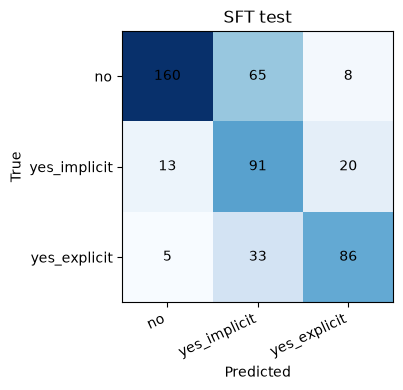

In [8]:
if not trainer.state.best_model_checkpoint:
    raise RuntimeError('Selesaikan training sebelum evaluasi test.')
results['sft_val'] = evaluate(val_records, 'sft_val')
test_records = [encode(row) for row in frames['test'].to_dict('records')]
results['sft_test'] = evaluate(test_records, 'sft_test')
if RUN_ZERO_SHOT_BASELINE:
    with model.disable_adapter():
        results['zero_shot_test'] = evaluate(test_records, 'zero_shot_test')
display(pd.DataFrame(results).T)

matrix = pd.read_csv(OUT / 'sft_test_confusion_matrix.csv', index_col=0)
fig, ax = plt.subplots(figsize=(5, 4))

ax.imshow(matrix, cmap='Blues')
ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS,
       xlabel='Predicted', ylabel='True', title='SFT test')

plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(matrix.iloc[i, j]), ha='center', va='center')
fig.tight_layout()
fig.savefig(OUT / 'sft_test_confusion_matrix.png', dpi=150)
plt.show()
plt.close(fig)


## 10. Simpan hasil dan unduh ZIP

- Simpan prompt, pengaturan, skor, prediksi, dan log pelatihan.
- Gabungkan laporan hasil ke dalam ZIP.
- Unduh ZIP melalui tautan di bawah atau panel Files Jupyter.



In [ ]:
(OUT / PROMPT_NAME).write_bytes(PROMPT_BYTES)
config = {'model': MODEL_NAME, 'revision': MODEL_COMMIT, 'language': DATA_LANGUAGE,
          'data_language': DATA_LANGUAGE, 'prompt_language': PROMPT_LANGUAGE, 'input_mode': INPUT_MODE,
          'system_prompt': SYSTEM_PROMPT, 'prompt_file': PROMPT_NAME,
          'label_to_answer': LABEL_TO_ANSWER, 'labels': LABELS, 'max_length': MAX_LENGTH,
          'enable_thinking': False, 'prediction': 'sum log P(label + im_end), no length normalization',
          'training': args.to_dict(), 'lora': lora.to_dict(), 'csv_sha256': source_hashes,
          'versions': {'torch': torch.__version__, 'transformers': transformers.__version__, 'peft': peft.__version__},
          'best_validation_macro_f1': trainer.state.best_metric,
          'best_model_checkpoint': trainer.state.best_model_checkpoint,
          'zero_shot_baseline': RUN_ZERO_SHOT_BASELINE,
          'train_metrics': train_result.metrics, 'adapter_exported': False}

for name, value in [('config', config), ('metrics', results)]:
    (OUT / f'{name}.json').write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
pd.DataFrame(results).T.to_csv(OUT / 'metrics.csv')

evaluation_names = ['sft_val', 'sft_test']

if RUN_ZERO_SHOT_BASELINE:
    evaluation_names += ['zero_shot_val', 'zero_shot_test']
required_reports = [PROMPT_NAME, 'config.json', 'metrics.json', 'metrics.csv',
                    'training_log.csv', 'trainer_state.json', 'sft_test_confusion_matrix.png']
required_reports += [f'{name}_{suffix}' for name in evaluation_names
                     for suffix in ('predictions.csv', 'report.csv', 'confusion_matrix.csv', 'metrics.json')]
missing_reports = [name for name in required_reports
                   if not (OUT / name).is_file() or (OUT / name).stat().st_size == 0]

if missing_reports:
    raise RuntimeError(f'Laporan belum lengkap. Jalankan evaluasi sebelum ekspor: {missing_reports}')
zip_path = OUT.with_suffix('.zip')
with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as archive:
    for file in OUT.rglob('*'):
        if file.is_file() and file.relative_to(OUT).parts[0] not in {'checkpoints', 'best_adapter'}:
            archive.write(file, file.relative_to(OUT.parent))
with ZipFile(zip_path) as archive:
    missing_in_zip = {f'{OUT.name}/{name}' for name in required_reports} - set(archive.namelist())
    bad_member = archive.testzip()

if missing_in_zip or bad_member:
    raise RuntimeError(f'ZIP gagal diverifikasi: missing={sorted(missing_in_zip)}, corrupt={bad_member}')
if OUT.resolve().is_relative_to(Path('/workspace').resolve()):
    import modal
    modal.Volume.from_name('ptm-qwen').commit()
    print('Hasil dan ZIP sudah di-commit ke Volume ptm-qwen.')


Hasil dan ZIP sudah di-commit ke Volume ptm-qwen.
ZIP terverifikasi: /__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951.zip
Jalankan di terminal PowerShell lokal untuk download:
$RunName = "qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951"
python -X utf8 -m modal volume get ptm-qwen "/results/$RunName.zip" "./Analisis/results/$RunName.zip"
Expand-Archive -LiteralPath "./Analisis/results/$RunName.zip" -DestinationPath "./Analisis/results/modal-qwen"
Simpan hasil lokal sebelum menghapus folder remote.


/__modal/volumes/vo-qUG9UHipNIZSMFuVhJKta7/results/qwen35_prompt-it_data-it_20261026T175537Z_e0dfc951.zip